In [1]:
import numpy as np
import pandas as pd

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_colwidth', 50000)
pd.set_option('display.max_columns', 50)

import seaborn as sns
import matplotlib.pyplot as plt

import predict_functions as pf

import datetime
from datetime import timedelta
from datetime import datetime

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
from sklearn.tree import export_graphviz
import pydot

import predict_functions as pf

import warnings
warnings.filterwarnings('ignore')

In [2]:
#гиперпараметр для обучения
is_hyper_search = 0

#список параметров для предсказания
predict_parameters = []

#временные рамки списка матчей для тренировочного и тестового наборов    
train_border1 = datetime.strptime("1994-06-01", "%Y-%m-%d")
train_border2 = datetime.strptime("2023-04-01", "%Y-%m-%d")

test_border1 = train_border2
test_border2 = datetime.strptime("2023-05-01", "%Y-%m-%d")

#ID лиг вторых дивизионов
second_leagues_lst = [
    141, # Spain Segunda
    40, # England championship
    136, # Italy Serie B
    79, # Germany Bundes 2
    62, # Frace Liga 2
]

In [3]:
data = pd.read_csv("C:\\Users\\vlkor\\PycharmProjects\\Прогнозирование результатов футбольных матчей/results.csv", encoding = 'cp1251', low_memory = False)
data

,match_id,HomeTeam,AwayTeam,HT_goals,AT_goals,Date,team_id,opponent_team_id,country,league,league_id,season,cf1,cfdr,cf2
0,1,M'gladbach,Bayern Munich,1.0,1.0,13/08/2021,194.0,161.0,Germany,Bundesliga,78,2022,4.33,4.50,1.66
1,2,Augsburg,Hoffenheim,0.0,4.0,14/08/2021,368.0,341.0,Germany,Bundesliga,78,2022,3.20,3.75,2.10
2,3,Bielefeld,Freiburg,0.0,0.0,14/08/2021,341.0,396.0,Germany,Bundesliga,78,2022,2.80,3.40,2.50
3,4,Stuttgart,Greuther Furth,5.0,1.0,14/08/2021,364.0,61.0,Germany,Bundesliga,78,2022,1.83,4.00,4.00
4,5,Union Berlin,Leverkusen,1.0,1.0,14/08/2021,264.0,272.0,Germany,Bundesliga,78,2022,2.75,3.40,2.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38689,38690,Murcia,Real Madrid B,1.0,0.0,07/06/14,369.0,244.0,Spain,Segunda,141,2014,2.30,3.30,3.10
38690,38691,Sabadell,Recreativo,0.0,0.0,07/06/14,79.0,180.0,Spain,Segunda,141,2014,2.25,3.30,3.20
38691,38692,Sp Gijon,Tenerife,3.0,0.0,07/06/14,82.0,206.0,Spain,Segunda,141,2014,1.17,7.00,15.00
38692,38693,Alcorcon,Zaragoza,1.0,0.0,08/06/14,143.0,112.0,Spain,Segunda,141,2014,1.85,3.50,3.50


In [4]:
len(data)

38694

In [5]:
data['Date'] = data['Date'].astype('datetime64[ns]').dt.date

In [6]:
data.sample(3)

,match_id,HomeTeam,AwayTeam,HT_goals,AT_goals,Date,team_id,opponent_team_id,country,league,league_id,season,cf1,cfdr,cf2
12556,12557,Millwall,Sheffield Weds,1.0,0.0,2019-08-17,187.0,391.0,England,Championship,40,2020,2.55,3.2,2.90
13588,13589,Wycombe,Bristol City,2.0,1.0,2021-04-21,187.0,295.0,England,Championship,40,2021,2.80,3.4,2.40
13893,13894,Barnsley,West Brom,0.0,0.0,2021-12-17,115.0,192.0,England,Championship,40,2022,5.00,3.8,1.66


In [7]:
data['league'].value_counts()

Championship      5495
Segunda           4565
Seria B           4132
Premier league    3734
Seria A           3730
LaLiga            3720
League 2          3640
League 1          3639
Bundesliga        3015
2.Bundesliga      3015
Name: league, dtype: int64

In [8]:
data['season'].value_counts()

2015    3993
2016    3990
2014    3990
2018    3988
2017    3988
2022    3906
2021    3906
2019    3868
2020    3705
2023    3360
Name: season, dtype: int64

In [9]:
data[['HT_goals']].describe()

,HT_goals
count,38685.000000
mean,1.452656
std,1.236451
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,10.000000


In [10]:
data[['HT_goals', 'AT_goals']].describe()

,HT_goals,AT_goals
count,38685.000000,38685.000000
mean,1.452656,1.136823
std,1.236451,1.108908
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,10.000000,9.000000


In [11]:
example = data.groupby(['HT_goals', 'AT_goals']).agg({'match_id': lambda x: x.nunique()})
example = example.sort_values(by='match_id', ascending=False)[0:10]
example.reset_index()

,HT_goals,AT_goals,match_id
0,1.0,1.0,4990
1,1.0,0.0,4163
2,2.0,1.0,3392
3,0.0,0.0,3217
4,0.0,1.0,3052
5,2.0,0.0,2963
6,1.0,2.0,2560
7,2.0,2.0,1985
8,0.0,2.0,1764
9,3.0,0.0,1585


In [12]:
data = pf.formatting(data, gh='HT_goals',ga='AT_goals')

In [13]:
team_based_data = pf.team_table(data)
team_based_data = team_based_data.merge(data[['match_id','country','league', 'league_id','season','cf1', 'cfdr', 'cf2']], 'left', on=['match_id'])

In [14]:
team_based_data['is_high_league'] = np.where(team_based_data['league'].isin(second_leagues_lst), 0, 1)

In [15]:
team_based_data.dropna(subset=['team'],inplace=True)

In [16]:
team_based_data.sample(3)

,index,match_id,date,team,opponent,venue,result,team_score,opponent_score,team_id,opponent_team_id,game_number,id,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1,cfdr,cf2,is_high_league
11770,8870,8871,2014-12-28,Sunderland,Aston Villa,Away,Draw,0.0,0.0,328.0,328.0,57,11802,1,0.5,1,0,0,1,13,19,25,57.0,87.0,England,Premier league,39,2015,2.35,3.30,3.40,1
42294,4332,4333,2018-10-27,FC Koln,Heidenheim,Home,Draw,1.0,1.0,45.0,284.0,183,42305,1,0.5,1,0,0,0,64,60,59,248.0,226.0,Germany,2.Bundesliga,79,2019,1.36,5.00,7.50,1
34010,16774,16775,2017-10-21,Nantes,Guingamp,Home,Win,2.0,1.0,104.0,389.0,162,33988,3,1.0,0,0,1,0,55,46,61,149.0,187.0,France,League 1,61,2018,2.10,3.29,3.75,1


In [17]:
team_based_data['team'].nunique()

290

In [18]:
team_based_data[['game_number']].describe()

,game_number
count,77370.000000
mean,165.006191
std,108.202690
min,1.000000
25%,70.000000
50%,154.000000
75%,251.000000
max,458.000000


In [19]:
team_based_data[['date']].describe(datetime_is_numeric = True)

,date
count,77370
mean,2018-05-30 03:34:11.120589568
min,2013-01-09 00:00:00
25%,2015-12-12 00:00:00
50%,2018-04-15 00:00:00
75%,2020-12-20 00:00:00
max,2023-12-03 00:00:00


In [20]:
results_at_home = pd.DataFrame(team_based_data[team_based_data['venue'] == 'Home'])
result_at_home = pd.DataFrame(results_at_home['result'].value_counts())
result_at_home['%'] = result_at_home['result']/ np.sum(result_at_home['result'])
result_at_home

,result,%
Win,16908,0.437069
Lose,11170,0.288742
Draw,10607,0.274189


## Разделение на тренировочный и тестовый наборы

In [21]:
team_based_data['y'] = team_based_data['result']
train_data, test_data = pf.df_date_split(team_based_data, train_border1, train_border2, test_border1, test_border2)
work_data = test_data.copy()
work_data = work_data.merge(team_based_data[['id', 'date','cf1','cfdr','cf2']], 'left', on='id')
work_data['date'] = work_data['date'].astype('datetime64[ns]').dt.date

train, len: 75824
test, len: 666


In [22]:
test_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y
76467,76469,Getafe,Mallorca,Away,319.0,319.0,Lose
75972,76033,Rotherham,QPR,Home,284.0,108.0,Win
76353,76368,Fortuna Dusseldorf,Nurnberg,Away,184.0,184.0,Lose


In [23]:
work_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,date,cf1,cfdr,cf2
530,76366,Frosinone,Sudtirol,Home,48.0,103.0,Draw,2023-04-22,1.6,3.6,6.5
10,75836,West Ham,Leeds,Away,185.0,185.0,Draw,2023-04-01,2.6,3.5,2.6
209,76015,Granada,Burgos,Away,215.0,215.0,Win,2023-04-03,3.5,2.9,2.3


In [24]:
work_data[(work_data['team'] == 'Paris FC') & (work_data['opponent'] == 'Guingamp')]

,id,team,opponent,venue,team_id,opponent_team_id,y,date,cf1,cfdr,cf2
144,75971,Paris FC,Guingamp,Home,197.0,389.0,Lose,2023-04-03,1.95,3.25,4.2


## Алгоритм моделирования

* форматирование (обработка данных для модели)

* дополнение (рейтингом Эло, статистикой матча и тд.)

* подготовка (выборка, нормализация и тд.)

* предсказывание (обучние модели)

* результат (оценка результата)

## Модель №1 (рандомные результаты)

In [25]:
# результат всегда рандомный
# форматирование: отсутствует
# дополнение: отсутствует
# подготовка: отсутствует

In [26]:
# предсказывание:
y_random_predict = test_data[['team', 'opponent']].apply(lambda x: pf.random_predict(x[0], x[1], seed=42), axis=1)
work_data['random_predict'] = y_random_predict.values

In [27]:
work_data

,id,team,opponent,venue,team_id,opponent_team_id,y,date,cf1,cfdr,cf2,random_predict
0,75847,Monza,Fiorentina,Away,315.0,315.0,Draw,2023-04-01,1.70,3.80,4.75,Draw
1,75828,Lecce,Lazio,Home,362.0,129.0,Win,2023-04-01,3.60,3.30,2.05,Win
2,75825,Cremonese,Juventus,Home,178.0,368.0,Lose,2023-04-01,4.75,3.80,1.67,Draw
3,75851,Salernitana,Milan,Home,68.0,301.0,Lose,2023-04-01,7.00,4.33,1.45,Lose
4,75835,Wolves,Aston Villa,Away,140.0,140.0,Draw,2023-04-01,1.95,3.60,4.00,Draw
...,...,...,...,...,...,...,...,...,...,...,...,...
661,76485,Blackburn,Burnley,Home,148.0,114.0,Lose,2023-04-25,3.40,3.40,2.15,Lose
662,76486,Sheffield United,West Brom,Home,134.0,192.0,Win,2023-04-26,2.05,3.30,3.80,Win
663,76487,West Brom,Sheffield United,Away,192.0,192.0,Lose,2023-04-26,2.05,3.30,3.80,Draw
664,76489,Rotherham,Cardiff,Home,284.0,329.0,Lose,2023-04-27,2.80,3.00,2.70,Win


,size,accuracy,f1,roi,segment,model
0,666,34.234234,33.936446,-3.771772,1,random


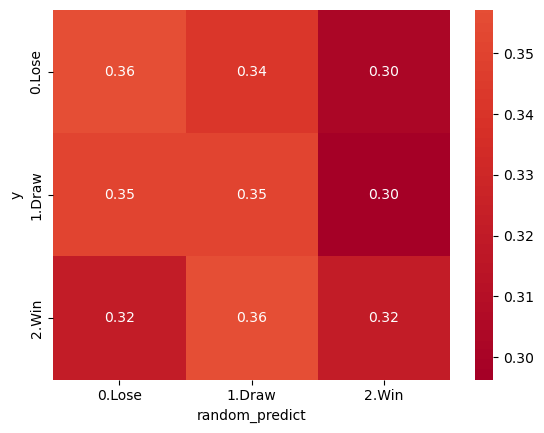

In [28]:
# результат
pf.model_results(work_data, 'random', 'random_predict', predict_parameters)

'rating_difference'


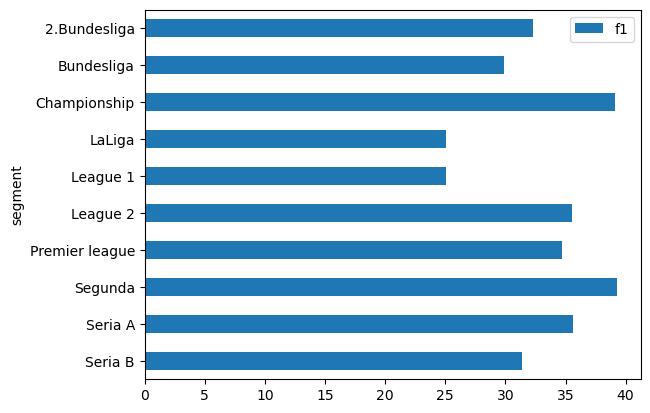

In [29]:
pd.set_option('mode.chained_assignment',None)
# оценка результата
work_data = work_data.merge(team_based_data, 'left', on='id', suffixes=('', '_enreached'))
leagues, venue, fi, comparison_data = pf.watching(work_data, 'random_predict', '', [], predict_parameters)

In [30]:
venue

,size,accuracy,f1,roi,segment
1,333,34.534535,33.907750,-1.810811,Home
0,333,33.933934,33.107611,-5.732733,Away


## Модель №2 (простое предсказание (хозяева всегда выигрывают))

In [31]:
# форматироварие: отсутствует
# дополнение: отсутствует
# подготовка: отсутствует

In [32]:
# предсказывание:
y_simple_predict = test_data[['team', 'opponent', 'venue']].apply(lambda x: pf.simple_predict(x[0], x[1], x[2]), axis=1)
work_data['simple_predict'] = y_simple_predict.values

In [33]:
work_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,date,cf1,cfdr,cf2,random_predict,revenue,global_segment,index,match_id,date_enreached,team_enreached,opponent_enreached,venue_enreached,result,team_score,opponent_score,team_id_enreached,opponent_team_id_enreached,game_number,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1_enreached,cfdr_enreached,cf2_enreached,is_high_league,y_enreached,simple_predict
344,76083,Crystal Palace,Southampton,Away,116.0,116.0,Win,2023-04-15,2.8,3.1,2.70,Draw,0.0,1,9750,9751,2023-04-15,Crystal Palace,Southampton,Away,Win,2.0,0.0,116.0,116.0,370,3,1.0,0,0,1,1,116,88,166,412.0,520.0,England,Premier league,39,2023,2.8,3.1,2.70,1,Win,Win
421,76205,Arsenal,West Ham,Away,55.0,55.0,Draw,2023-04-16,6.0,4.2,1.55,Draw,4.2,1,9754,9755,2023-04-16,Arsenal,West Ham,Away,Draw,2.0,2.0,55.0,55.0,370,1,0.5,1,0,0,0,205,73,92,668.0,422.0,England,Premier league,39,2023,6.0,4.2,1.55,1,Draw,Win
512,76379,Salernitana,Sassuolo,Home,68.0,323.0,Win,2023-04-22,3.1,3.5,2.25,Lose,0.0,1,26265,26266,2023-04-22,Salernitana,Sassuolo,Home,Win,3.0,0.0,68.0,323.0,303,3,1.0,0,0,1,1,90,100,113,351.0,427.0,Italy,Seria A,135,2023,3.1,3.5,2.25,1,Win,Win


,size,accuracy,f1,roi,segment,model
0,666,37.837838,18.300654,-0.121622,1,simple_predict


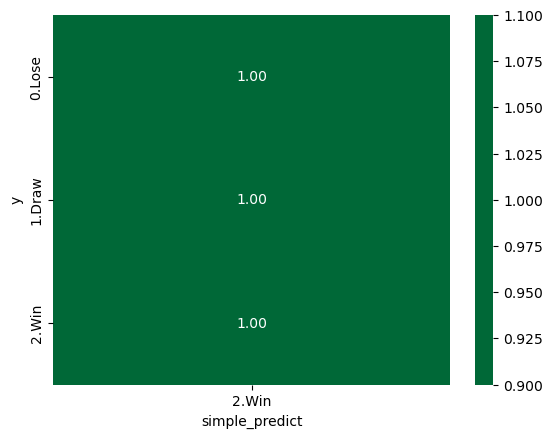

In [34]:
# результат
pf.model_results(work_data, 'simple_predict', 'simple_predict', predict_parameters)

'rating_difference'


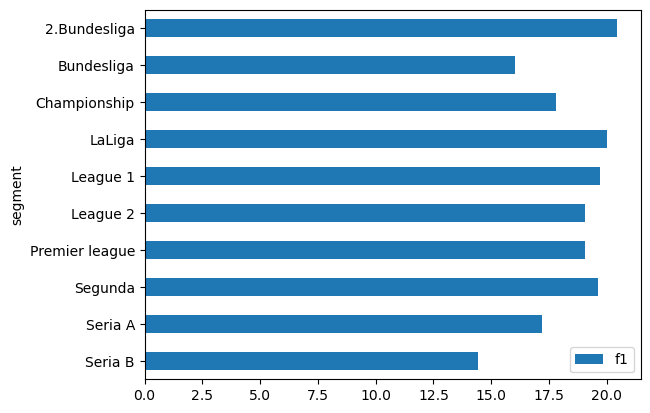

In [35]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'simple_predict', '', [], predict_parameters)

In [36]:
venue

,size,accuracy,f1,roi,segment
1,333,46.546547,21.174863,4.681682,Home
0,333,29.129129,15.038760,-4.924925,Away


In [37]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict


## Модель №3 (модель с рейтингом Эло)

In [38]:
# дополнение: рейтинг Эло для команд

# рассчет рейтинга Эло (добавление его в статистику, создание словаря со значениями рейтинга Эло каждой команды)
team_based_data, dct = pf.count_elo_rating_df(team_based_data)

In [39]:
# обновленные и подсчитанные рейтинги
current_game_num = team_based_data.groupby('team')[['game_number']].max().reset_index()

with_now_data = team_based_data.merge(current_game_num, 'left', on='team', suffixes=('', '_fresh'))
now_data = with_now_data[with_now_data['game_number'] == with_now_data['game_number_fresh']]

In [40]:
now_data.sample(3)

,index,match_id,date,team,opponent,venue,result,team_score,opponent_score,team_id,opponent_team_id,game_number,id,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1,cfdr,cf2,is_high_league,y,rating,opponent_rating,rating_difference,elo_propability,game_number_fresh
273974,9709,9710,2023-12-03,Southampton,Man United,Away,Draw,0.0,0.0,329.0,329.0,374,77336,1,0.5,1,0,0,1,121,96,157,458.0,540.0,England,Premier league,39,2023,1.36,5.00,9.0,1,Draw,2479.09,2761.24,-282.15,0.16,374
273727,18808,18809,2023-12-02,Brest,Montpellier,Away,Lose,0.0,3.0,184.0,184.0,364,77275,0,0.0,0,1,0,0,138,105,121,461.0,430.0,France,League 1,61,2023,2.38,3.30,3.0,1,Lose,2431.37,2492.67,-61.30,0.41,364
273601,9706,9707,2023-11-03,Nott'm Forest,Tottenham,Away,Lose,1.0,3.0,186.0,186.0,446,77189,0,0.0,0,1,0,0,149,131,166,549.0,565.0,England,Premier league,39,2023,1.44,4.75,7.0,1,Lose,2386.54,2649.65,-263.11,0.18,446


In [41]:
now_data[['rating']].describe()

,rating
count,1007.000000
mean,2326.653704
std,190.744926
min,1864.030000
25%,2202.785000
50%,2318.070000
75%,2449.390000
max,2878.140000


In [42]:
now_data.groupby(['season']).agg({'team': lambda x: x.nunique(),'rating': lambda x: np.round(np.mean(x),0)})

,team,rating
season,,
2014,10,2239.0
2015,5,2273.0
2016,7,2179.0
2017,3,2172.0
2018,11,2307.0
2019,13,2167.0
2020,10,2210.0
2021,13,2100.0
2022,16,2144.0


In [43]:
lgs = now_data.groupby(['league']).agg({'team': lambda x: x.nunique(), 'rating': lambda x: np.round(np.mean(x),0)})
lgs.sort_values(by='rating', ascending=False)

,team,rating
league,,
LaLiga,20,2607.0
Premier league,20,2570.0
Seria A,20,2522.0
Bundesliga,18,2502.0
League 1,20,2458.0
Championship,36,2262.0
Segunda,48,2255.0
2.Bundesliga,29,2239.0
Seria B,43,2223.0


In [44]:
bts = now_data.groupby(['team']).agg({'rating': lambda x: np.round(np.mean(x),0),'game_number': np.mean})
best_teams = bts.sort_values(by='rating', ascending=False)[0:20]
best_teams

,rating,game_number
team,,
Barcelona,2878.0,372.0
Paris SG,2848.0,363.0
Ath Madrid,2817.0,372.0
Man City,2802.0,372.0
Man United,2785.0,372.0
Liverpool,2781.0,373.0
Newcastle,2773.0,381.0
Real Madrid,2773.0,372.0
Arsenal,2753.0,374.0


<Axes: title={'center': 'Milan'}, xlabel='game_number'>

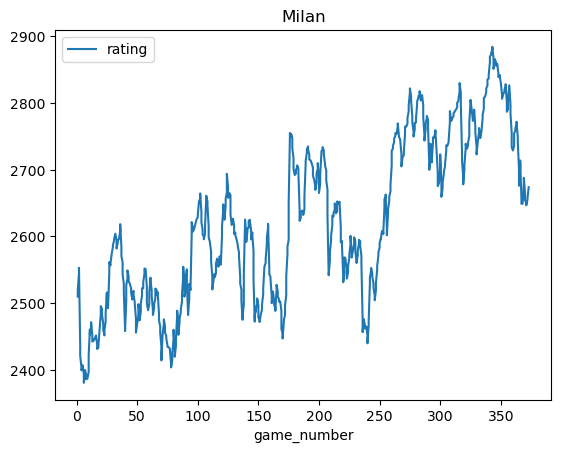

In [45]:
# динамика рейтинга команды
current_team = 'Milan'
dt = team_based_data[team_based_data['team'] == current_team]
dt = dt[['team', 'game_number', 'date', 'rating']]
dt.set_index('game_number')[['rating']].plot(title=current_team)

<Axes: xlabel='game_number', ylabel='rating'>

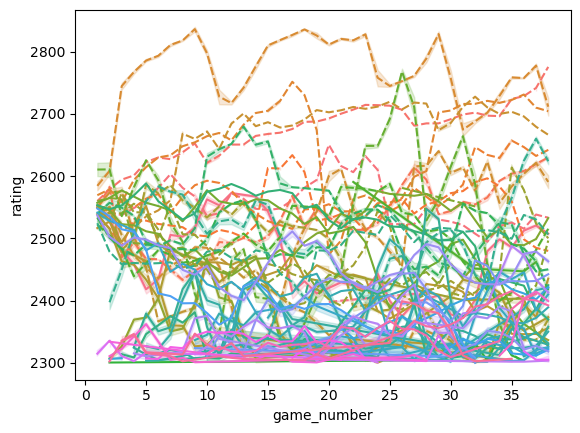

In [46]:
# динамика рейтинга команд 1 и 2 лиг Испании, имеющих рейтинг > 2300
sns.lineplot(
    data = team_based_data[(team_based_data['game_number'] <= 38) & (team_based_data['country'] == 'Spain') & (team_based_data['rating'] > 2300)], 
    x = 'game_number', 
    y = 'rating', 
    hue = 'team',
    legend = False,
    style = 'league',
            )

<Axes: xlabel='game_number', ylabel='rating'>

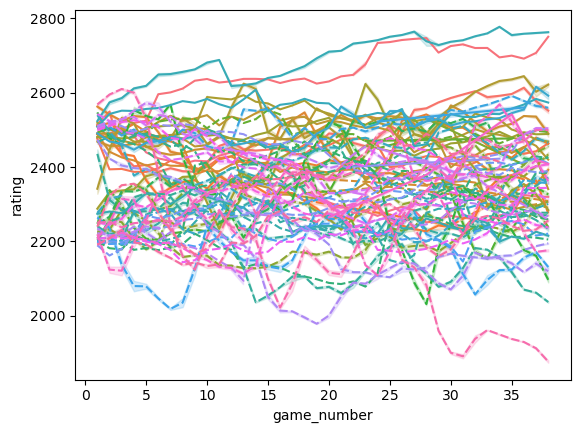

In [47]:
sns.lineplot(
    data=team_based_data[
        (team_based_data['game_number'] <= 38) &
        (team_based_data['country'] == 'Italy')
                        ], 
    x='game_number', 
    y='rating', 
    hue='team',
    legend=False,
    style='league'
            )

<Axes: xlabel='game_number', ylabel='rating'>

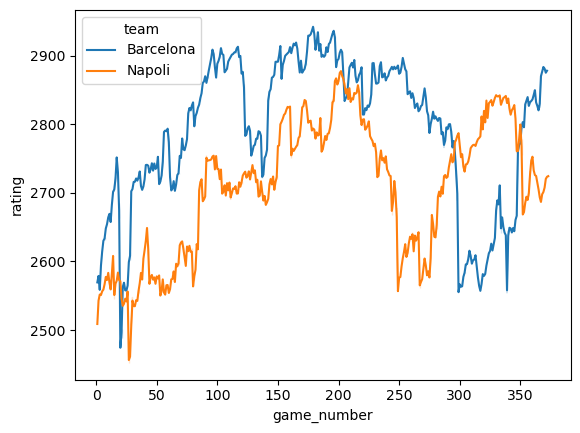

In [48]:
sns.lineplot(
    data = team_based_data[(team_based_data['team'].isin(['Napoli', 'Barcelona']))], 
    x = 'game_number', 
    y = 'rating', 
    hue = 'team',
    legend = True,
            )

In [49]:
# дополнение
# рассчет рейтинга Эло для тренировочного набора
train_data, current_rating_dict = pf.count_elo_rating_df(train_data)

In [50]:
# подготовка данных (добавляем столбцы с рейтингом):
test_data['rating'] = test_data['team'].map(current_rating_dict) 
test_data['opponent_rating'] = test_data['opponent'].map(current_rating_dict) 
test_data['rating_difference'] = test_data['rating'] - test_data['opponent_rating']

td = test_data[['rating', 'opponent_rating']]
test_data['elo_propability'] = td.apply(lambda x: np.round(pf.elo_prob(x[0], x[1]),2), axis=1)

In [51]:
test_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,rating,opponent_rating,rating_difference,elo_propability
76312,76340,Ibiza,Oviedo,Home,327.0,291.0,Lose,2275.17,2353.22,-78.05,0.39
76063,76072,Regensburg,Greuther Furth,Away,230.0,230.0,Lose,2200.12,2419.03,-218.91,0.22
75988,76041,Sandhausen,Holstein Kiel,Home,174.0,250.0,Draw,2148.58,2292.42,-143.84,0.30


In [52]:
# предсказывание:
y_direct_elo = test_data['elo_propability'].apply(lambda x: pf.elo_prob_predict(x, 0.1))
work_data['direct_elo_predict'] = y_direct_elo.values

,size,accuracy,f1,roi,segment,model
0,666,39.339339,38.881302,-12.246246,1,direct_elo


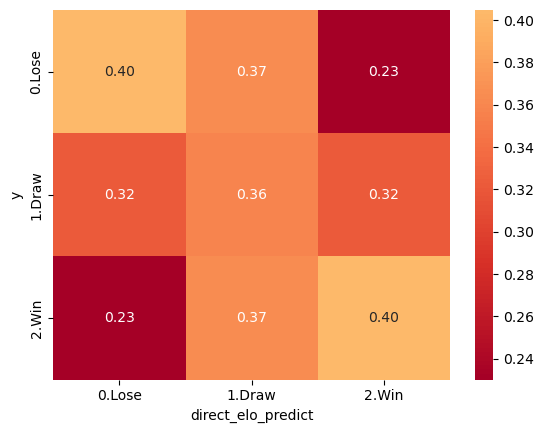

In [53]:
# результат:
pf.model_results(work_data, 'direct_elo', 'direct_elo_predict', predict_parameters)

'rating_difference'


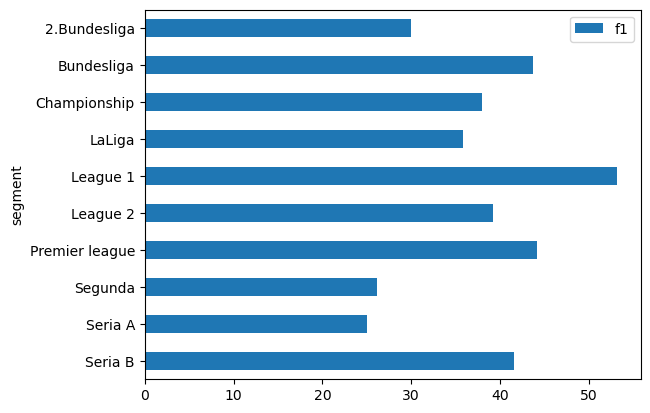

In [54]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'direct_elo_predict', '', [], predict_parameters)

In [55]:
venue

,size,accuracy,f1,roi,segment
0,333,39.339339,38.39924,-12.246246,Away
1,333,39.339339,38.39924,-12.246246,Home


In [56]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo


## Модель №4 (метод случайного леса с рейтингом Эло)

In [57]:
train_data.sample(3)

,index,match_id,date,team,opponent,venue,result,team_score,opponent_score,team_id,opponent_team_id,game_number,id,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1,cfdr,cf2,is_high_league,y,rating,opponent_rating,rating_difference,elo_propability
90616,35124,35125,2016-09-25,Cadiz,Oviedo,Home,Lose,0.0,2.0,117.0,291.0,10,25389,0,0.0,0,1,0,0,3,3,4,9.0,11.0,Spain,Segunda,141,2017,2.15,3.25,3.40,1,Lose,2456.03,2245.68,210.35,0.77
24769,22497,22498,2014-04-25,Nancy,Lens,Away,Draw,1.0,1.0,329.0,329.0,36,6779,1,0.5,1,0,0,0,14,12,10,41.0,37.0,France,League 2,62,2014,2.05,3.20,3.75,1,Draw,2345.22,2369.33,-24.11,0.47
15801,9284,9285,2014-01-18,Man City,Cardiff,Home,Win,4.0,2.0,289.0,329.0,21,4364,3,1.0,0,0,1,0,15,2,4,61.0,25.0,England,Premier league,39,2014,1.13,11.00,23.00,1,Win,2673.91,2424.59,249.32,0.81


In [58]:
test_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,rating,opponent_rating,rating_difference,elo_propability
76196,76224,Villarreal B,Leganes,Away,186.0,186.0,Lose,2380.24,2293.50,86.74,0.62
76131,76195,Hoffenheim,Bayern Munich,Away,341.0,341.0,Draw,2473.78,2665.93,-192.15,0.25
76021,75979,Atalanta,Udinese,Home,225.0,215.0,Draw,2557.64,2619.52,-61.88,0.41


In [59]:
# подготовка (нормализация данные):
train_data['rating_difference_normalized'] = MinMaxScaler(feature_range=(-1,1)).fit_transform(train_data[['rating_difference']])

test_data['rating_difference_normalized'] = MinMaxScaler(feature_range=(-1,1)).fit_transform(test_data[['rating_difference']])

x_fields = ['rating_difference_normalized']

X_train = train_data[x_fields]
y_train = train_data['y'].values

X_test = test_data[x_fields]
y_test = test_data['y'].values

In [60]:
# предсказывание:
elo_clf = RandomForestClassifier(n_estimators = 100, max_depth = 8, min_samples_split = 3, max_features = 'sqrt', bootstrap = False, random_state = 22)

elo_clf.fit(X_train, y_train)

y_elo_rf_pred = elo_clf.predict(X_test)
work_data['elo_rf_predict'] = y_elo_rf_pred

In [61]:
# выведем одно из наших деревьев как рисунок
tree = elo_clf.estimators_[5]

export_graphviz(tree, out_file = 'tree_example.dot', feature_names = x_fields, rounded = True, precision = 1)
(graph, ) = pydot.graph_from_dot_file('tree_example.dot')
graph.write_png('tree_example.png');

,size,accuracy,f1,roi,segment,model
0,666,41.891892,36.851324,-9.575075,1,random_forest_elo


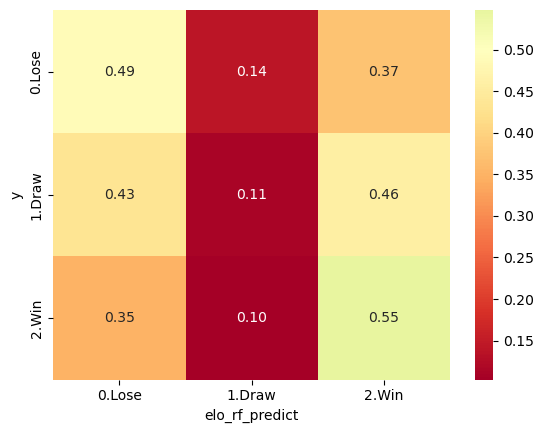

In [62]:
# результат:
pf.model_results(work_data, 'random_forest_elo', 'elo_rf_predict', predict_parameters)

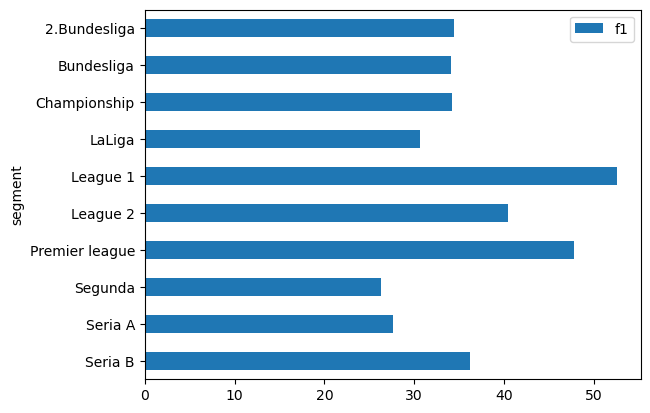

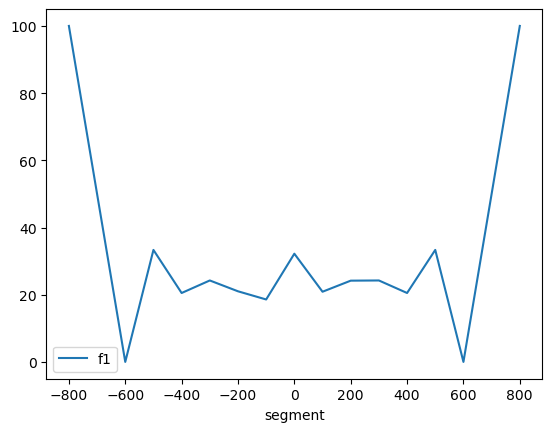

In [63]:
work_data['rating_difference'] = test_data['rating_difference'].values
leagues, venue, fi, comparison_data = pf.watching(work_data, 'elo_rf_predict', elo_clf, x_fields, predict_parameters)

In [64]:
venue

,size,accuracy,f1,roi,segment
0,333,42.342342,36.619795,-7.534535,Away
1,333,41.441441,36.267812,-11.615616,Home


In [65]:
fi

,feature,importance,position
0,rating_difference_normalized,1.0,0


In [66]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo


In [67]:
diffs = work_data[(work_data['direct_elo_predict'] != work_data['elo_rf_predict'])]

In [68]:
diffs['result'].value_counts()

Win     68
Lose    60
Draw    41
Name: result, dtype: int64

In [69]:
diffs[['team', 'opponent', 'rating_difference', 'direct_elo_predict', 'elo_rf_predict']].sort_values(by='rating_difference')

,team,opponent,rating_difference,direct_elo_predict,elo_rf_predict
658,Tenerife,Huesca,-73.59,Draw,Lose
308,Frosinone,Cagliari,-73.42,Draw,Lose
37,Holstein Kiel,Kaiserslautern,-73.32,Draw,Lose
350,Hull,Blackburn,-72.21,Draw,Lose
608,Leverkusen,RB Leipzig,-71.20,Draw,Lose
...,...,...,...,...,...
654,Huesca,Tenerife,73.59,Draw,Win
548,Millwall,Wigan,124.75,Win,Draw
615,Mallorca,Getafe,124.90,Win,Draw
6,Fiorentina,Monza,224.84,Win,Lose


## Модель №5 (модель №4 c дополнительными параметрами)

In [70]:
# дополнение (создадим столбцы категориальных переменных is_Home и is_Away:
venue_ohe = pd.get_dummies(train_data['venue'], prefix='is')
train_data['is_Home'] = venue_ohe['is_Home']
train_data['is_Away'] = venue_ohe['is_Away']

venue_ohe = pd.get_dummies(test_data['venue'], prefix='is')
test_data['is_Home'] = venue_ohe['is_Home']
test_data['is_Away'] = venue_ohe['is_Away']

nd = now_data[['team', 'match_id','wins', 'draws', 'loses', 'scored', 'mised','is_high_league']]
test_data = test_data.merge(nd, 'left', on='team', suffixes=('', '_enreached'))

In [71]:
test_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,rating,opponent_rating,rating_difference,elo_propability,rating_difference_normalized,is_Home,is_Away,match_id,wins,draws,loses,scored,mised,is_high_league
1597,76303,Angers,Paris SG,Home,391.0,233.0,Lose,2059.51,2832.31,-772.80,0.01,-1.000000,1,0,18848,113,101,150,396.0,477.0,1
1765,76388,Mainz,Bayern Munich,Home,293.0,161.0,Win,2637.66,2665.93,-28.27,0.46,-0.036581,1,0,2965,116,78,141,453.0,513.0,1
1059,76144,Guingamp,Amiens,Home,389.0,164.0,Win,2150.14,2188.41,-38.27,0.45,-0.049521,1,0,22104,114,103,147,417.0,498.0,1


In [72]:
train_data.sample(3)

,index,match_id,date,team,opponent,venue,result,team_score,opponent_score,team_id,opponent_team_id,game_number,id,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1,cfdr,cf2,is_high_league,y,rating,opponent_rating,rating_difference,elo_propability,rating_difference_normalized,is_Home,is_Away
80331,10815,10816,2016-04-16,QPR,Cardiff,Away,Draw,0.0,0.0,108.0,108.0,122,22381,1,0.5,1,0,0,1,41,32,49,147.0,164.0,England,Championship,40,2016,2.00,3.60,4.0,1,Draw,2353.68,2394.48,-40.80,0.44,-0.055728,0,1
70391,34782,34783,2015-12-19,Alaves,Ponferradina,Away,Win,1.0,0.0,163.0,163.0,102,19626,3,1.0,0,0,1,1,37,26,39,129.0,127.0,Spain,Segunda,141,2016,2.30,3.10,3.3,1,Win,2485.57,2296.70,188.87,0.75,0.272034,0,1
78250,32977,32978,2016-03-13,Villarreal,Sevilla,Away,Lose,2.0,4.0,45.0,45.0,106,21799,0,0.0,0,1,0,0,49,29,28,145.0,104.0,Spain,LaLiga,140,2016,1.73,3.75,5.0,1,Lose,2623.26,2624.89,-1.63,0.50,0.000171,0,1


In [73]:
x_fields_minus_plus = ['rating_difference']

x_fields_zero_one = ['wins', 'loses']
x_stable = ['is_Home', 'is_high_league']

X_train = pf.normalize_df(train_data, x_fields_minus_plus, x_fields_zero_one, x_stable)
X_test = pf.normalize_df(test_data, x_fields_minus_plus, x_fields_zero_one, x_stable)

y_train = train_data['y'].values
y_test = test_data['y'].values

In [74]:
X_train.dropna(inplace=True)

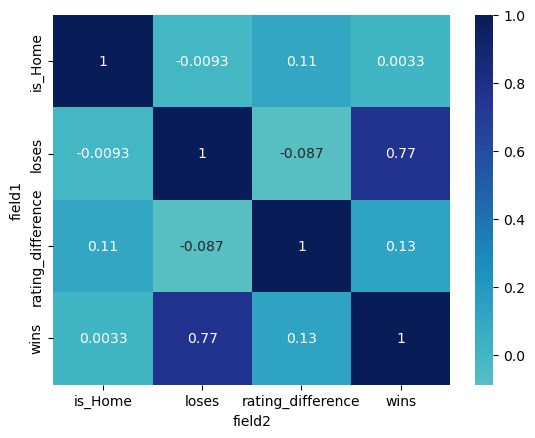

In [75]:
problems = pf.show_fields(X_train, 0.7)

In [76]:
problems

,correlation,field1,field2
7,0.769491,wins,loses
11,0.769491,loses,wins


In [77]:
# предсказывание:
real_elo_clf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_split = 3, max_features = 'sqrt', bootstrap = False, random_state=22)

real_elo_clf.fit(X_train, y_train)

X_test.drop_duplicates(inplace=True)
y_real_elo_rf_pred = real_elo_clf.predict(X_test)
work_data['real_elo_rf_predict'] = y_real_elo_rf_pred

,size,accuracy,f1,roi,segment,model
0,666,42.492492,36.249211,-11.106607,1,real_random_forest_elo


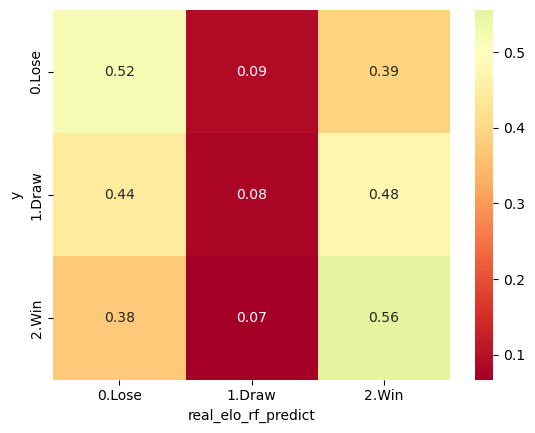

In [78]:
pf.model_results(work_data, 'real_random_forest_elo', 'real_elo_rf_predict', predict_parameters)

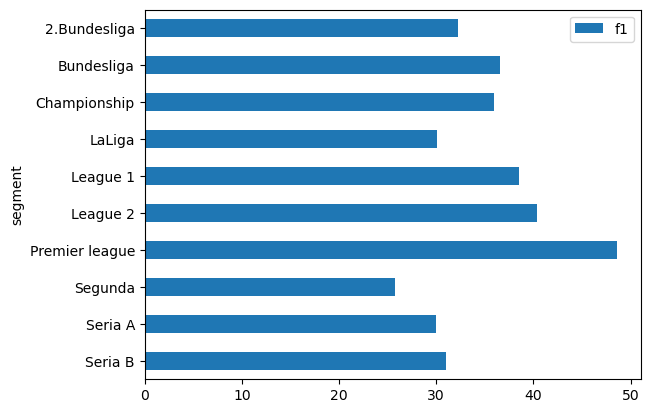

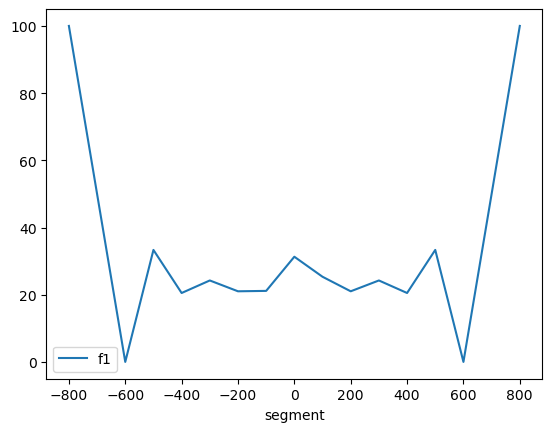

In [79]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'real_elo_rf_predict', real_elo_clf, X_train.columns, predict_parameters)

In [80]:
venue

,size,accuracy,f1,roi,segment
0,333,41.741742,36.726996,-12.789790,Away
1,333,43.243243,33.310506,-9.423423,Home


In [81]:
fi

,feature,importance,position
0,rating_difference,0.851118,0
1,is_Home,0.084446,1
2,wins,0.035353,2
3,loses,0.029082,3
4,is_high_league,0.000000,4


In [82]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo
4,666,42.492492,36.249211,-11.106607,real_random_forest_elo


In [83]:
work_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,date,cf1,cfdr,cf2,random_predict,revenue,global_segment,index,match_id,date_enreached,team_enreached,opponent_enreached,venue_enreached,result,team_score,opponent_score,team_id_enreached,opponent_team_id_enreached,...,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1_enreached,cfdr_enreached,cf2_enreached,is_high_league,y_enreached,simple_predict,direct_elo_predict,elo_rf_predict,rating_difference,rating_difference_bins,real_elo_rf_predict
189,76053,Wolves,Tottenham,Home,140.0,103.0,Win,2023-04-03,3.30,3.4,2.20,Draw,0.00,1,9697,9698,2023-04-03,Wolves,Tottenham,Home,Win,1.0,0.0,140.0,103.0,...,1.0,0,0,1,1,146,92,125,451.0,431.0,England,Premier league,39,2023,3.30,3.4,2.20,1,Win,Win,Lose,Lose,-132.14,-100.0,Lose
371,76114,Birmingham,Sunderland,Away,255.0,255.0,Lose,2023-04-15,1.91,3.5,4.33,Lose,1.91,1,14679,14680,2023-04-15,Birmingham,Sunderland,Away,Lose,1.0,2.0,255.0,255.0,...,0.0,0,1,0,0,130,131,191,493.0,640.0,England,Championship,40,2023,1.91,3.5,4.33,1,Lose,Win,Lose,Lose,-81.92,-100.0,Lose
221,75990,Swansea,Luton,Away,192.0,192.0,Lose,2023-04-03,2.00,3.3,4.00,Lose,2.00,1,14592,14593,2023-04-03,Swansea,Luton,Away,Lose,0.0,1.0,192.0,192.0,...,0.0,0,1,0,0,147,103,161,509.0,556.0,England,Championship,40,2023,2.00,3.3,4.00,1,Lose,Win,Lose,Lose,-142.70,-100.0,Lose


In [84]:
diff = work_data[work_data['elo_rf_predict'] != work_data['real_elo_rf_predict']]

diff[['team', 'opponent', 'rating_difference', 'elo_rf_predict', 'real_elo_rf_predict']].sort_values(by='rating_difference')

,team,opponent,rating_difference,elo_rf_predict,real_elo_rf_predict
616,Leganes,Alaves,-65.48,Draw,Lose
109,Brescia,Perugia,-63.98,Lose,Draw
26,Leeds,West Ham,-62.88,Lose,Draw
248,Toulouse,Lyon,-54.56,Draw,Lose
432,Mallorca,Celta,-29.29,Draw,Lose
...,...,...,...,...,...
450,Huddersfield,Sunderland,122.74,Win,Draw
548,Millwall,Wigan,124.75,Draw,Win
615,Mallorca,Getafe,124.90,Draw,Win
636,Fiorentina,Monza,224.84,Lose,Win


## Модель №6 (модель №5 с гиперпараметрами)

In [85]:
if is_hyper_search == 1:
    
    n_range = range(6, 300)
    d_range = range(7, 24)
    
    best_n, best_depth = pf.hypeparams_fit(X_train, y_train, X_test, test_data,n_range,d_range)
    
else:
    
    best_n = 300
    best_depth = 22

In [86]:
best_params_elo_clf = RandomForestClassifier(n_estimators=best_n,
                                             max_depth=best_depth,
                                             min_samples_split = 3,
                                             max_features = 'sqrt',
                                             bootstrap = False, random_state=22)

best_params_elo_clf.fit(X_train, y_train)

y_best_params = best_params_elo_clf.predict(X_test)
work_data['best_params_elo_predict'] = y_best_params

,size,accuracy,f1,roi,segment,model
0,666,41.741742,37.68859,-7.741742,1,best_params_elo


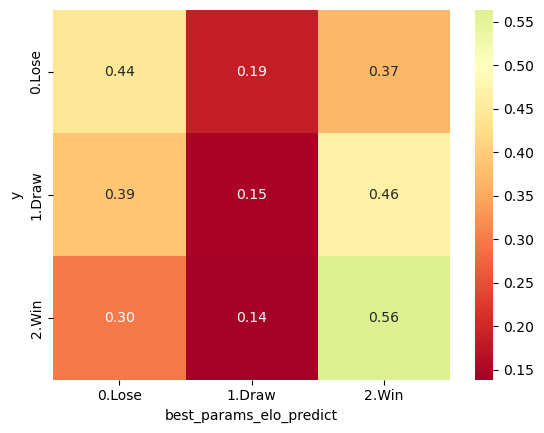

In [87]:
pf.model_results(work_data, 'best_params_elo', 'best_params_elo_predict', predict_parameters)

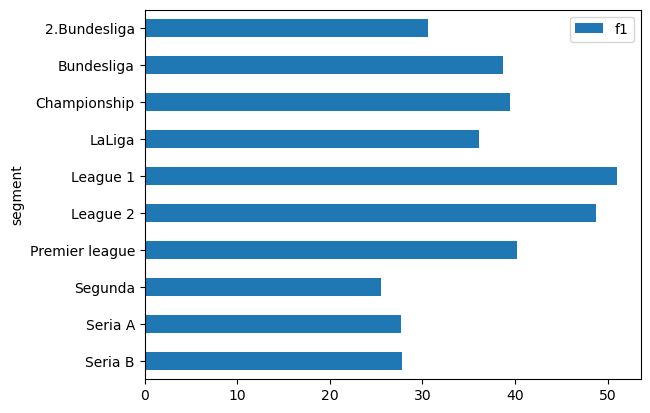

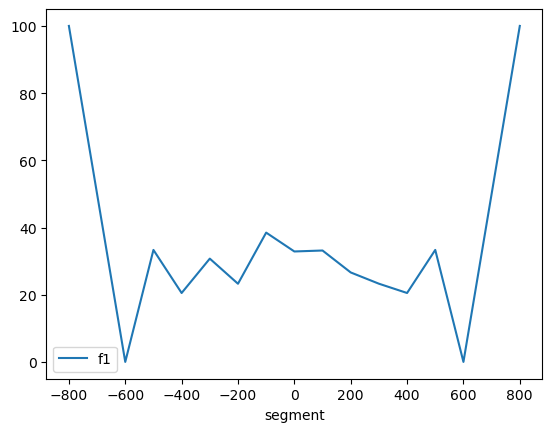

In [88]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'best_params_elo_predict', best_params_elo_clf, X_train.columns, predict_parameters)

In [89]:
venue

,size,accuracy,f1,roi,segment
1,333,47.147147,40.449714,5.387387,Home
0,333,36.336336,32.686482,-20.870871,Away


In [90]:
fi

,feature,importance,position
0,rating_difference,0.556408,0
1,loses,0.206986,1
2,wins,0.205549,2
3,is_Home,0.031057,3
4,is_high_league,0.000000,4


In [91]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo
4,666,42.492492,36.249211,-11.106607,real_random_forest_elo
5,666,41.741742,37.688590,-7.741742,best_params_elo


In [92]:
dif = work_data[(work_data['best_params_elo_predict'] != work_data['elo_rf_predict'])]
dif = dif[['team', 'opponent', 'rating_difference', 'wins', 'loses', 'venue', 'is_high_league','elo_rf_predict', 'best_params_elo_predict']]
dif.sample(3)

,team,opponent,rating_difference,wins,loses,venue,is_high_league,elo_rf_predict,best_params_elo_predict
144,Paris FC,Guingamp,-7.57,90,73,Home,1,Draw,Lose
404,Auxerre,Nantes,-39.05,123,127,Home,1,Lose,Win
87,Celta,Betis,2.24,120,146,Away,1,Draw,Lose


## Модель №7 (модель с учетом личных встреч команд)

In [93]:
tbd = team_based_data.copy()
tbd.drop_duplicates(subset=['match_id','team'],inplace=True)
tbd.dropna(subset=['team'], inplace=True)

In [94]:
%%time
# личные встречи
tbd, curr_stat_dct = pf.calc_pers_stat_df(tbd)

tbd['result_difference_personal_meet'] = tbd['wins_personal_meet'] - tbd['loses_personal_meet']

tbd['result_difference_venue'] = tbd['wins_venue'] - tbd['loses_venue']

tbd['games_personal_meet'] = tbd['wins_personal_meet'] + tbd['loses_personal_meet'] + tbd['draws_personal_meet']
                                        
tbd['games_venue'] = tbd['wins_venue'] + tbd['loses_venue'] + tbd['draws_venue']

CPU times: total: 1.56 s
Wall time: 3.48 s


In [95]:
tbd.drop_duplicates(inplace=True)

In [96]:
nd = now_data.copy()
nd.drop_duplicates(subset=['match_id','team'],inplace=True)

In [97]:
pers_stat_df = pd.DataFrame.from_dict(curr_stat_dct, orient='index').reset_index()

pers_stat_df['team1'] = pers_stat_df['index'].apply(lambda x: x.split('-')[0])
pers_stat_df['team2'] = pers_stat_df['index'].apply(lambda x: x.split('-')[1])
pers_stat_df = pers_stat_df[1:]
pers_stat_df.columns = ['index','wins','draws','loses','scored','missed','wins_home','draws_home','loses_home','scored_home','missed_home',
            'wins_away','draws_away','loses_away','scored_away','missed_away','team1', 'team2']

pers_stat_df['results_difference'] = pers_stat_df['wins'] - pers_stat_df['loses']
pers_stat_df['games'] = pers_stat_df['wins'] + pers_stat_df['loses'] + pers_stat_df['draws']
pers_stat_df = pers_stat_df[['team1', 'team2', 'results_difference', 'games']]

team_data = tbd[tbd['season'] == 2021][['team', 'league']].drop_duplicates()

pers_stat_df = pers_stat_df.merge(team_data, 'left', left_on='team1',right_on='team')
pers_stat_df = pers_stat_df.merge(team_data, 'left', left_on='team2', right_on='team',suffixes=('_team1', '_team2'))
pers_stat_df = pers_stat_df.merge(nd[['team', 'rating']], 'left', left_on='team1',right_on='team')
pers_stat_df = pers_stat_df.merge(nd[['team', 'rating']], 'left', left_on='team2', right_on='team',suffixes=('_team1', '_team2'))
pers_stat_df = pers_stat_df.drop(columns=['team_team1','team_team2','team_team1','team_team2'])

pers_stat_df['rating_difference'] = pers_stat_df['rating_team1'] - pers_stat_df['rating_team2']

In [98]:
pers_stat_df.drop_duplicates(inplace=True)

In [99]:
def get_league_heat_map(pers_stat_df, league):
    
    pers_stat_pv = pers_stat_df[(pers_stat_df['league_team1'] == league) & (pers_stat_df['league_team2'] == league)]
    pers_stat_pv = pers_stat_pv.pivot_table(index='team1', columns='team2', values='results_difference')
    pers_stat_pv = pers_stat_pv.fillna(0).reset_index()

    pers_stat_pv = pers_stat_pv.merge(nd[['team', 'rating']], 'left', left_on='team1',right_on='team')
    
    pers_stat_pv = pers_stat_pv.sort_values(by='rating', ascending=False)
    pers_stat_pv = pers_stat_pv.drop(columns=['team', 'rating']).set_index('team1')

    sns.heatmap(
                pers_stat_pv, 
                cmap="RdYlGn", 
                annot=True,
                center=0,
                )

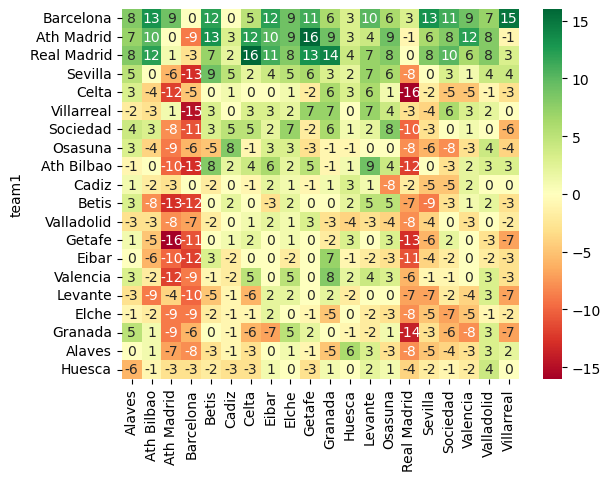

In [100]:
get_league_heat_map(pers_stat_df, 'LaLiga')

In [101]:
enreached_data = pers_stat_df[
    (pers_stat_df['rating_difference'] < 0) &
    (pers_stat_df['results_difference'] > 0) &
    (pers_stat_df['league_team1'] == pers_stat_df['league_team2']) & 
    (pers_stat_df['games'] > 3)]

In [102]:
len(enreached_data)

452

In [103]:
team_based_data.sample(3)

,index,match_id,date,team,opponent,venue,result,team_score,opponent_score,team_id,opponent_team_id,game_number,id,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1,cfdr,cf2,is_high_league,y,rating,opponent_rating,rating_difference,elo_propability
68798,9007,9008,2015-12-04,Man City,Man United,Away,Lose,2.0,4.0,289.0,289.0,90,19145,0,0.0,0,1,0,0,59,14,17,214.0,91.0,England,Premier league,39,2015,2.63,3.4,2.88,1,Lose,2717.63,2710.44,7.19,0.51
1687,22252,22253,2013-04-10,Laval,Auxerre,Away,Lose,0.0,2.0,301.0,301.0,3,438,0,0.0,0,1,0,0,1,0,2,5.0,4.0,France,League 2,62,2014,1.80,3.3,4.75,1,Lose,2404.30,2407.49,-3.19,0.50
103546,19924,19925,2017-02-24,Laval,Bourg Peronnas,Home,Lose,2.0,4.0,301.0,279.0,139,29001,0,0.0,0,1,0,0,34,60,45,141.0,158.0,France,League 2,62,2017,2.05,3.0,4.20,1,Lose,2166.36,2336.42,-170.06,0.27


In [104]:
pers_stat_df.groupby('league_team1').mean()[['games']]

,games
league_team1,
2.Bundesliga,7.171344
Bundesliga,10.261618
Championship,7.982805
LaLiga,8.907005
League 1,8.932668
League 2,6.445465
Premier league,9.374226
Segunda,6.196721
Seria A,8.653618


In [105]:
train_data, curr_stat_dct = pf.calc_pers_stat_df(train_data)

In [106]:
def spl(txt):
    
    txt = txt.replace(' ', '')
    txt = txt[1:-1]
    lst = txt.split(',')

    res_lst = []
    for l in lst:
        res_lst.append(int(float(l)))
    
    return res_lst

test_data['caption'] = test_data['team'] + '-' + test_data['opponent']

mask = '[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]'
match_stat_ser = test_data['caption'].map(curr_stat_dct).fillna(str(mask))
match_stat_ser = match_stat_ser.apply(lambda x: spl(str(x)))

pers_stat = pd.DataFrame.from_dict(dict(zip(match_stat_ser.index, match_stat_ser.values))).T
pers_stat['id'] = test_data['id'].values
pers_stat_df_venue = pf.pers_stat_venue(pers_stat)

test_data = test_data.merge(pers_stat_df_venue, 'left', on=['id', 'venue'], suffixes=('', '_personal_meet'))

In [107]:
x_fields_minus_plus = ['rating_difference', 'result_difference_personal_meet']

x_fields_zero_one = ['wins', 'loses']

x_stable = ['is_Home', 'is_high_league']

X_train = pf.normalize_df(train_data, x_fields_minus_plus, x_fields_zero_one, x_stable)
X_test = pf.normalize_df(test_data, x_fields_minus_plus, x_fields_zero_one, x_stable)

y_train = train_data['y'].values
y_test = test_data['y'].values

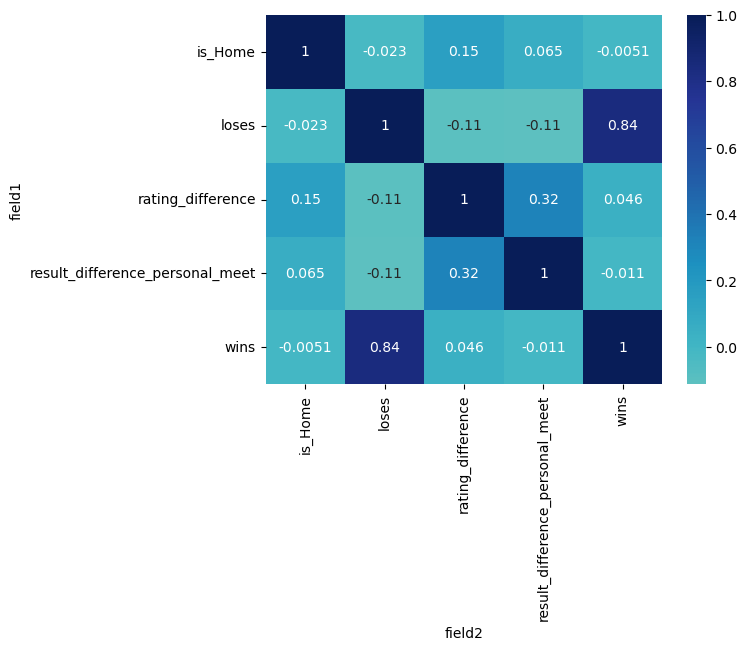

In [108]:
problems = pf.show_fields(X_train, 0.7)

In [109]:
problems

,correlation,field1,field2
15,0.836913,wins,loses
20,0.836913,loses,wins


,size,accuracy,f1,roi,segment,model
0,666,42.342342,33.324782,-7.584084,1,with_pers_meets


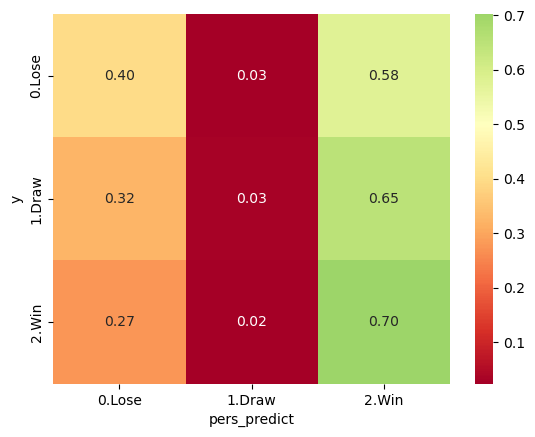

In [110]:
pers_clf = RandomForestClassifier(n_estimators=100, max_depth=17, min_samples_split = 3, max_features = 'sqrt', bootstrap = False, random_state=42)

pers_clf.fit(X_train, y_train)
X_test.drop_duplicates(inplace=True)

y_pers = pers_clf.predict(X_test)
work_data['pers_predict'] = y_pers

pf.model_results(work_data, 'with_pers_meets', 'pers_predict', predict_parameters)

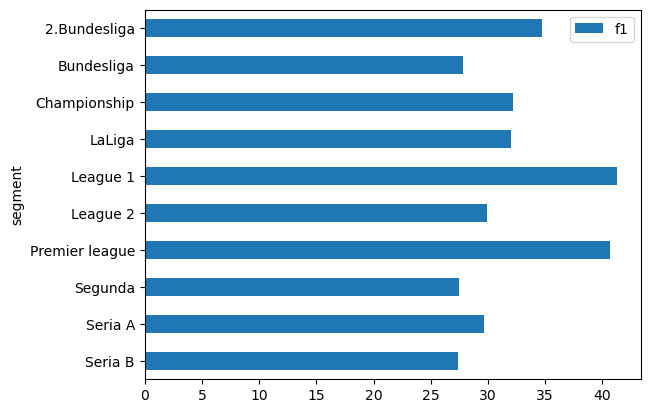

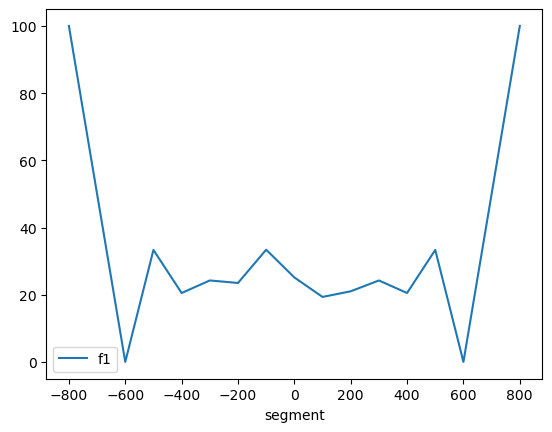

In [111]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'pers_predict', pers_clf, X_train.columns, predict_parameters)

In [112]:
venue

,size,accuracy,f1,roi,segment
0,333,41.141141,34.399532,-5.564565,Away
1,333,43.543544,30.813751,-9.603604,Home


In [113]:
fi

,feature,importance,position
0,rating_difference,0.403016,0
1,result_difference_personal_meet,0.300677,1
2,wins,0.136270,2
3,loses,0.135640,3
4,is_Home,0.024397,4
5,is_high_league,0.000000,5


In [114]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo
4,666,42.492492,36.249211,-11.106607,real_random_forest_elo
5,666,41.741742,37.688590,-7.741742,best_params_elo
6,666,42.342342,33.324782,-7.584084,with_pers_meets


In [115]:
work_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,date,cf1,cfdr,cf2,random_predict,revenue,global_segment,index,match_id,date_enreached,team_enreached,opponent_enreached,venue_enreached,result,team_score,opponent_score,team_id_enreached,opponent_team_id_enreached,...,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1_enreached,cfdr_enreached,cf2_enreached,is_high_league,y_enreached,simple_predict,direct_elo_predict,elo_rf_predict,rating_difference,rating_difference_bins,real_elo_rf_predict,best_params_elo_predict,pers_predict
534,76410,Auxerre,Lille,Home,398.0,389.0,Draw,2023-04-22,4.50,4.0,1.70,Win,0.0,1,18893,18894,2023-04-22,Auxerre,Lille,Home,Draw,1.0,1.0,398.0,389.0,...,0,0,0,123,109,127,425.0,423.0,France,League 1,61,2023,4.50,4.0,1.70,1,Draw,Win,Lose,Lose,-249.40,-200.0,Lose,Draw,Lose
411,76197,Torino,Salernitana,Home,393.0,68.0,Draw,2023-04-16,1.73,3.5,5.25,Win,0.0,1,26260,26261,2023-04-16,Torino,Salernitana,Home,Draw,1.0,1.0,393.0,68.0,...,0,0,0,121,119,126,503.0,508.0,Italy,Seria A,135,2023,1.73,3.5,5.25,1,Draw,Win,Win,Win,88.62,100.0,Win,Win,Win
308,76177,Frosinone,Cagliari,Away,48.0,48.0,Draw,2023-04-15,2.50,3.2,3.00,Lose,0.0,1,29934,29935,2023-04-15,Frosinone,Cagliari,Away,Draw,0.0,0.0,48.0,48.0,...,0,0,1,131,99,115,428.0,428.0,Italy,Seria B,136,2023,2.50,3.2,3.00,1,Draw,Win,Draw,Lose,-73.42,-100.0,Lose,Lose,Lose


## Модель №8 (модель №7 с гиперпараметрами)

In [116]:
%%time
if is_hyper_search == 1:
    n_range = range(6, 20)
    d_range = range(7, 24)

    best_n, best_depth = pf.hypeparams_fit(X_train, y_train, X_test, test_df, n_range, d_range)
    
else:
    best_n = 300
    best_depth = 22

CPU times: total: 0 ns
Wall time: 0 ns


In [117]:
best_pers_clf = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=22)

best_pers_clf.fit(X_train, y_train)
X_test.drop_duplicates(inplace=True)

y_best_pers = best_pers_clf.predict(X_test)
work_data['best_pers_predict'] = y_best_pers

,size,accuracy,f1,roi,segment,model
0,666,43.543544,33.240452,-2.636637,1,pers_meets_hyperparams


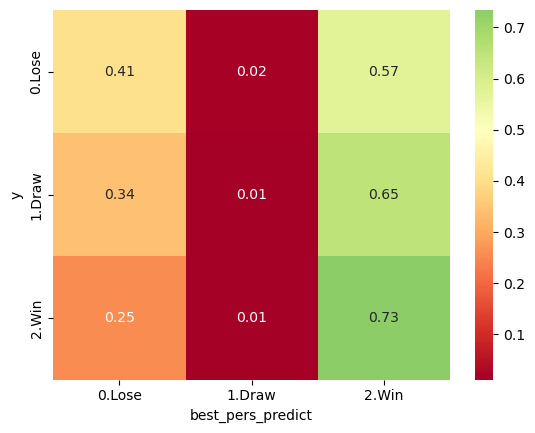

In [118]:
pf.model_results(work_data, 'pers_meets_hyperparams', 'best_pers_predict', predict_parameters)

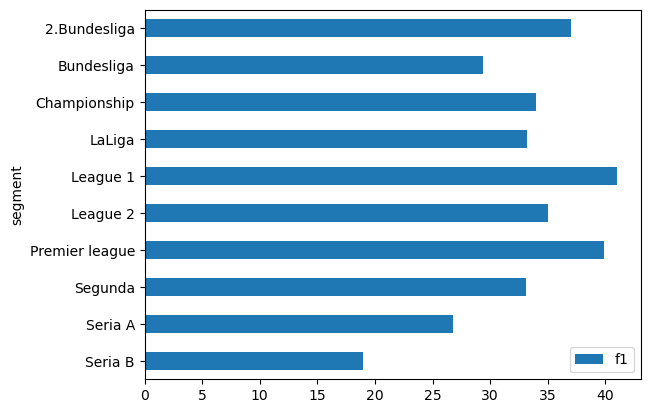

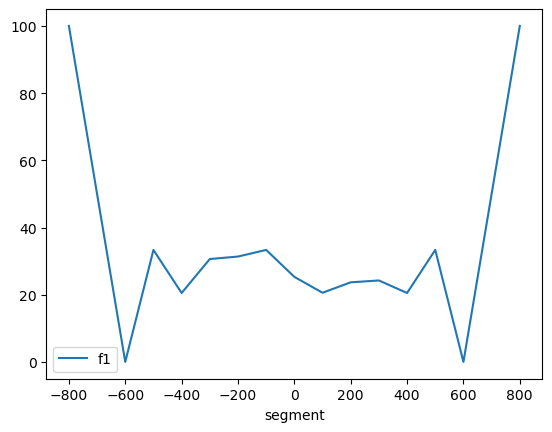

In [119]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'best_pers_predict', best_pers_clf, X_train.columns, predict_parameters)

In [120]:
venue

,size,accuracy,f1,roi,segment
0,333,42.642643,33.855107,0.165165,Away
1,333,44.444444,31.239478,-5.438438,Home


In [121]:
fi

,feature,importance,position
0,rating_difference,0.358893,0
1,result_difference_personal_meet,0.270928,1
2,loses,0.176526,2
3,wins,0.174677,3
4,is_Home,0.018976,4
5,is_high_league,0.000000,5


In [122]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo
4,666,42.492492,36.249211,-11.106607,real_random_forest_elo
5,666,41.741742,37.688590,-7.741742,best_params_elo
6,666,42.342342,33.324782,-7.584084,with_pers_meets
7,666,43.543544,33.240452,-2.636637,pers_meets_hyperparams


## Модель #9 (модель с подробной статистикой матчей)

In [123]:
match_stat = pd.read_csv("C:\\Users\\vlkor\\PycharmProjects\\Прогнозирование результатов футбольных матчей/match_stat.csv", encoding = 'cp1251', low_memory = False)

In [124]:
# дополнение (добавляем статистику матчей)
team_based_data = team_based_data.merge(match_stat, 'left', on=['match_id', 'team'], suffixes=('', '_stat')).fillna(0)

team_based_data['shots_accuracy'] = (team_based_data['shots_on_goal'] / team_based_data['total_shots']).fillna(0)

In [125]:
def get_stat_df(df, fields, method):
    
    stat_df = df.groupby(fields).agg(
        games = ('match_id', 'count'),
        points = ('points', method),
        wins = ('is_Win', method),
        draws = ('is_Draw', method),
        loses = ('is_Lose', method),
        scored = ('team_score', method),
        mised = ('opponent_score', method),
        dry = ('is_dry_match', method),
        shots = ('total_shots', method),
        shots_on_goal = ('shots_on_goal', method),
        fouls = ('fouls', method),
        corners = ('corners', 'mean'),
        yellow_cards = ('yellow_cards', method),
    )
    
    stat_df['score_diff'] = stat_df['scored'] - stat_df['mised'] 
    
    stat_df['goals_per_game'] = np.round(stat_df['scored'] / stat_df['games'], 2)
    
    stat_df['win_rate'] = np.round(stat_df['wins'] / stat_df['games'] , 2)
    
    stat_df['peacefullaty'] = np.round(stat_df['draws'] / stat_df['games'] , 2)
    
    stat_df['dryality'] = np.round(stat_df['dry'] / stat_df['games'] , 2)
    
    stat_df['shots_accuracy'] = np.round(stat_df['shots_on_goal'] / stat_df['shots'],2)
    
    rdf = df.loc[df.groupby(fields)['date'].idxmax()]
    rating_df = rdf.set_index(fields)[['rating']].reset_index()
    
    stat_df = stat_df.merge(rating_df, 'left', on=fields).set_index(fields)
    
    stat_df=stat_df[['games', 'points', 'rating', 'wins', 'draws', 'loses','scored', 'mised', 'score_diff', 'goals_per_game','dry', 'dryality',
        'win_rate', 'peacefullaty','shots', 'shots_on_goal', 'shots_accuracy','corners', 'fouls','yellow_cards']].reset_index()
    
    return stat_df

In [126]:
get_stat_df(team_based_data[(team_based_data['league'] == 'La Liga') & (team_based_data['season'] <= 2015)],
            ['team'],
            'sum'
           ).columns

Index(['team', 'games', 'points', 'rating', 'wins', 'draws', 'loses', 'scored',
       'mised', 'score_diff', 'goals_per_game', 'dry', 'dryality', 'win_rate',
       'peacefullaty', 'shots', 'shots_on_goal', 'shots_accuracy', 'corners',
       'fouls', 'yellow_cards'],
      dtype='object')

In [127]:
get_stat_df(
            team_based_data[(team_based_data['league'] == 'LaLiga') & (team_based_data['season'] <= 2016) & (team_based_data['venue'] == 'Home')],
            ['team'],
            'sum'
           )

,team,games,points,rating,wins,draws,loses,scored,mised,score_diff,goals_per_game,dry,dryality,win_rate,peacefullaty,shots,shots_on_goal,shots_accuracy,corners,fouls,yellow_cards
0,Almeria,69,74,2282.01,17,23,29,89.0,109.0,-20.0,1.29,23,0.33,0.25,0.33,777.0,270.0,0.35,5.057971,1048.0,201.0
1,Ath Bilbao,105,208,2626.15,61,25,19,195.0,98.0,97.0,1.86,36,0.34,0.58,0.24,1465.0,524.0,0.36,6.733333,1357.0,207.0
2,Ath Madrid,297,726,2770.06,222,60,15,624.0,159.0,465.0,2.10,174,0.59,0.75,0.20,4254.0,1638.0,0.39,7.141414,3963.0,678.0
3,Barcelona,105,268,2759.39,87,7,11,349.0,71.0,278.0,3.32,48,0.46,0.83,0.07,1825.0,856.0,0.47,6.590476,1121.0,154.0
4,Betis,138,148,2484.24,36,40,62,126.0,176.0,-50.0,0.91,38,0.28,0.26,0.29,2036.0,604.0,0.30,6.028986,1828.0,404.0
5,Celta,465,730,2475.88,195,145,125,615.0,520.0,95.0,1.32,150,0.32,0.42,0.31,6425.0,2125.0,0.33,5.924731,6045.0,1005.0
6,Cordoba,66,34,2454.04,4,22,40,44.0,108.0,-64.0,0.67,12,0.18,0.06,0.33,702.0,182.0,0.26,4.606061,828.0,132.0
7,Eibar,70,84,2475.50,22,18,30,86.0,91.0,-5.0,1.23,13,0.19,0.31,0.26,813.0,290.0,0.36,4.214286,1050.0,193.0
8,Elche,69,73,2387.00,18,19,32,49.0,76.0,-27.0,0.71,22,0.32,0.26,0.28,803.0,206.0,0.26,5.492754,1050.0,215.0
9,Espanol,105,166,2485.88,44,34,27,120.0,113.0,7.0,1.14,44,0.42,0.42,0.32,1129.0,408.0,0.36,5.019048,1749.0,282.0


In [128]:
get_stat_df(
            team_based_data[(team_based_data['league'] == 'LaLiga') & (team_based_data['season'] <= 2016) & (team_based_data['venue'] == 'Home')],
            ['team'],
            'mean'
           ).sample(3)

,team,games,points,rating,wins,draws,loses,scored,mised,score_diff,goals_per_game,dry,dryality,win_rate,peacefullaty,shots,shots_on_goal,shots_accuracy,corners,fouls,yellow_cards
9,Espanol,105,1.580952,2485.88,0.419048,0.323810,0.257143,1.142857,1.076190,0.066667,0.01,0.419048,0.00,0.00,0.0,10.752381,3.885714,0.36,5.019048,16.657143,2.685714
16,Osasuna,35,1.028571,2341.64,0.285714,0.171429,0.542857,0.914286,1.400000,-0.485714,0.03,0.257143,0.01,0.01,0.0,14.800000,5.114286,0.35,6.857143,12.857143,1.685714
1,Ath Bilbao,105,1.980952,2626.15,0.580952,0.238095,0.180952,1.857143,0.933333,0.923810,0.02,0.342857,0.00,0.01,0.0,13.952381,4.990476,0.36,6.733333,12.923810,1.971429


In [129]:
team_based_data_stat = team_based_data[team_based_data['fouls']>0]

In [130]:
team_based_data_stat.sample(3)

,index,match_id,date,team,opponent,venue,result,team_score,opponent_score,team_id,opponent_team_id,game_number,id,points,score,is_Draw,is_Lose,is_Win,is_dry_match,wins,draws,loses,scored,mised,country,league,league_id,season,cf1,cfdr,cf2,is_high_league,y,rating,opponent_rating,rating_difference,elo_propability,total_shots,shots_on_goal,fouls,corners,yellow_cards,shots_accuracy
204771,28947,28948,2020-12-12,Reggiana,Cosenza,Away,Win,1.0,0.0,391.0,391.0,10,57565,3,1.0,0,0,1,1,4,2,4,13.0,17.0,Italy,Seria B,136,2021,2.05,3.3,3.6,1,Win,2252.10,2166.52,85.58,0.62,10.0,6.0,20.0,4.0,3.0,0.600000
257125,37885,37886,2022-09-17,Sp Gijon,Zaragoza,Away,Lose,0.0,1.0,82.0,82.0,379,72323,0,0.0,0,1,0,0,136,118,125,437.0,413.0,Spain,Segunda,141,2023,2.25,3.1,3.5,1,Lose,2331.55,2246.84,84.71,0.62,11.0,1.0,10.0,4.0,4.0,0.090909
210475,13386,13387,2021-01-30,Nott'm Forest,Barnsley,Home,Draw,0.0,0.0,186.0,115.0,348,59100,1,0.5,1,0,0,1,113,104,131,432.0,450.0,England,Championship,40,2021,2.45,3.2,3.0,1,Draw,2358.17,2328.80,29.37,0.54,6.0,1.0,10.0,4.0,1.0,0.166667


In [131]:
team_based_data_stat.groupby('league')[['total_shots']].describe()

total_shots                                                  
                     count       mean       std  min   25%   50%   75%   max
league                                                                      
2.Bundesliga       10403.0  13.018264  4.698121  0.0  10.0  13.0  16.0  33.0
Bundesliga         13573.0  12.678332  4.992889  0.0   9.0  12.0  16.0  36.0
Championship       47029.0  12.240936  4.710797  0.0   9.0  12.0  15.0  43.0
LaLiga             28147.0  11.358369  4.644592  0.0   8.0  11.0  14.0  36.0
League 1           28448.0  11.445585  4.508522  0.0   8.0  11.0  14.0  37.0
League 2           12334.0  10.867926  4.344691  1.0   8.0  10.0  13.0  35.0
Premier league     22973.0  12.621512  5.401542  0.0   9.0  12.0  16.0  43.0
Segunda            18197.0  10.918558  4.259920  0.0   8.0  11.0  13.0  42.0
Seria A            24961.0  12.042787  5.054298  0.0   8.0  11.0  15.0  46.0
Seria B            19692.0  11.831302  4.811576  0.0   8.0  12.0  15.0  31.0

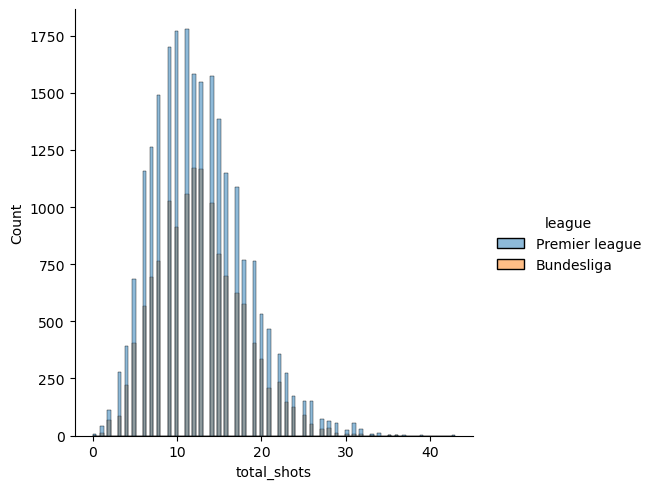

In [132]:
sns.displot(
            data=team_based_data_stat[team_based_data_stat['league'].isin(['Premier league','Bundesliga'])], 
            x='total_shots', 
            hue='league')

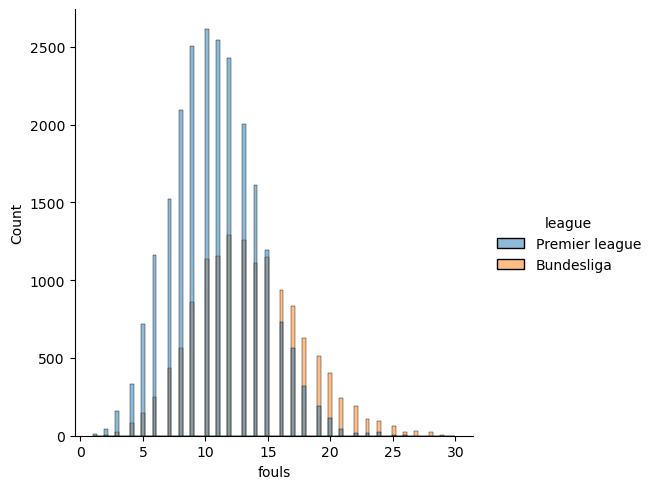

In [133]:
sns.displot(
            data=team_based_data_stat[team_based_data_stat['league'].isin(['Premier league','Bundesliga'])], 
            x="fouls", 
            hue="league")

<Axes: xlabel='total_shots', ylabel='team_score'>

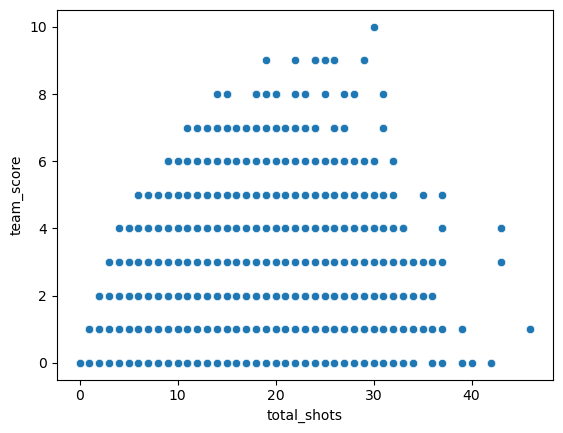

In [134]:
team_based_data_stat['team_score'] = team_based_data_stat['team_score'].astype('int')
sns.scatterplot(data=team_based_data_stat, x='total_shots', y='team_score')

In [135]:
work_lst = ['wins', 'draws', 'loses', 'scored','mised', 'score_diff','dry','shots', 'shots_on_goal', 'shots_accuracy','corners','fouls','yellow_cards']

In [136]:
train_data = train_data.merge(match_stat, 'left', on=['match_id', 'team'], suffixes=('', '_stat')).fillna(0)

train_data['shots_accuracy'] = (train_data['shots_on_goal'] / train_data['total_shots']).fillna(0)

In [137]:
train_data = train_data[train_data['fouls']>0]
train_data.drop_duplicates(inplace=True)

In [138]:
ma_list = ['shots_on_goal', 'fouls','corners']
ma_list_ma = []

In [139]:
for col in ma_list:
    train_data[col+'_ma'] = np.where(
                        train_data['game_number'] <= 10, train_data[col],
                        train_data.groupby('team_id')[col].transform(lambda x: x.rolling(8, 1).mean()))
    
    ma_list_ma.append(col+'_ma')

fresh_game_num = train_data.groupby('team_id').max()['game_number'].reset_index()

fresh_game_num.columns = ['team_id', 'last_game']

train_data = train_data.merge(fresh_game_num, 'left', on='team_id')

fresh_data = train_data[train_data['game_number'] == train_data['last_game']]

ma_list_ma.append('team_id')
stat_dct = fresh_data[ma_list_ma]

In [140]:
stat_dct.sample(3)

,shots_on_goal_ma,fouls_ma,corners_ma,team_id
806863,2.0,9.0,4.0,391.0
956214,6.0,7.0,4.0,137.0
806867,2.0,9.0,4.0,391.0


In [141]:
test_data = test_data.merge(stat_dct, 'left', on=['team_id'], suffixes=('', '_stat')).fillna(0)

In [142]:
test_data.sample(3)

,id,team,opponent,venue,team_id,opponent_team_id,y,rating,opponent_rating,rating_difference,elo_propability,rating_difference_normalized,is_Home,is_Away,match_id,wins,draws,loses,scored,mised,is_high_league,caption,wins_personal_meet,draws_personal_meet,loses_personal_meet,scored_personal_meet,missed_personal_meet,wins_venue,draws_venue,loses_venue,scored_venue,missed_venue,result_difference_personal_meet,result_difference_venue,games_personal_meet,games_venue,shots_on_goal_ma,fouls_ma,corners_ma
362546,76229,Angers,Clermont,Away,391.0,391.0,Lose,2059.51,2351.45,-291.94,0.16,-0.377769,0,1,18848,113,101,150,396.0,477.0,1,Angers-Clermont,5,50,40,95,150,0,50,25,75,125,-35,-25,95,75,2.0,9.0,4.0
724915,76418,Tottenham,Newcastle,Away,103.0,103.0,Lose,2613.47,2736.11,-122.64,0.33,-0.158696,0,1,9707,203,73,98,665.0,423.0,1,Tottenham-Newcastle,63,12,24,213,138,54,9,9,180,108,39,45,99,72,3.0,8.0,3.0
281783,76137,Metz,Bordeaux,Home,184.0,163.0,Win,2365.98,2453.34,-87.36,0.38,-0.113043,1,0,22016,131,98,135,430.0,479.0,1,Metz-Bordeaux,16,52,116,112,368,0,36,36,48,144,-100,-36,184,72,4.0,13.0,5.0


In [143]:
train_data.drop_duplicates(subset=['id'],inplace=True)

In [144]:
test_data.drop_duplicates(subset=['id'], inplace=True)

In [145]:
x_fields_minus_plus = ['rating_difference', 'result_difference_personal_meet']

x_fields_zero_one = ['wins', 'loses', 'shots_on_goal_ma', 'fouls_ma', 'corners_ma']

x_stable = ['is_Home', 'is_high_league']

In [146]:
X_train = pf.normalize_df(train_data, x_fields_minus_plus, x_fields_zero_one, x_stable)
X_test = pf.normalize_df(test_data, x_fields_minus_plus, x_fields_zero_one, x_stable)

y_train = train_data['y'].values
y_test = test_data['y'].values

In [147]:
X_train.dropna(inplace=True)

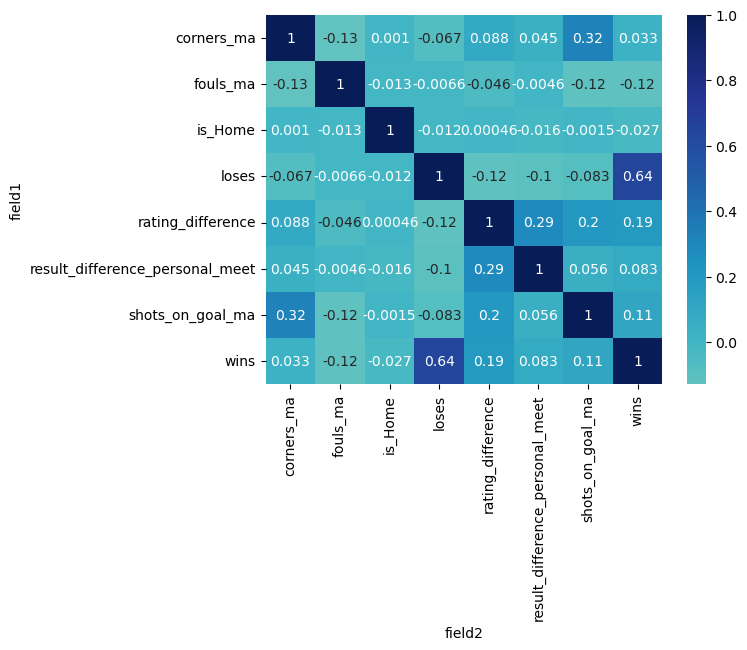

In [148]:
problems = pf.show_fields(X_train, 0.75)

In [149]:
tw0 = test_data[['is_Home','is_high_league']].reset_index(drop=True)

lst = X_train.index[X_train['wins']!= 'nan'].tolist()

y_train_new = y_train.copy()
y_train = np.array([y_train[i] for i in lst], dtype='object')

In [150]:
X_test.dropna(subset=['rating_difference'],inplace=True)
X_test.drop(columns=['is_Home','is_high_league'],axis=1,inplace=True)

In [151]:
X_test = pd.concat([X_test,tw0],axis=1)

In [152]:
stat_clf = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=22)

stat_clf.fit(X_train, y_train)
X_test.drop_duplicates(inplace=True)

y_stat = stat_clf.predict(X_test)
work_data['match_stat_predict'] = y_stat

,size,accuracy,f1,roi,segment,model
0,666,37.837838,35.721012,-10.153153,1,with_match_stat


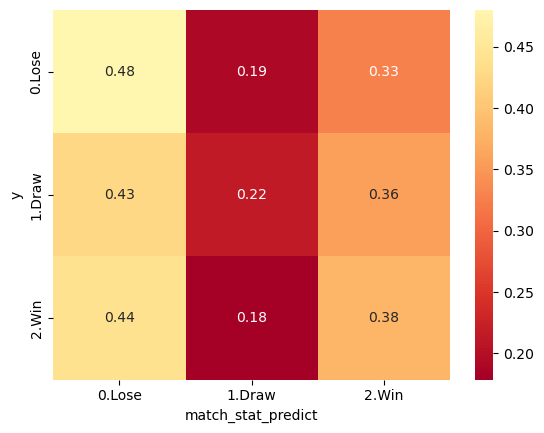

In [153]:
pf.model_results(work_data, 'with_match_stat', 'match_stat_predict', predict_parameters)

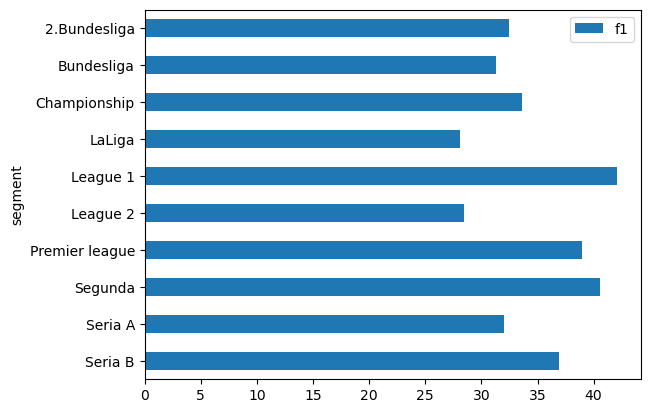

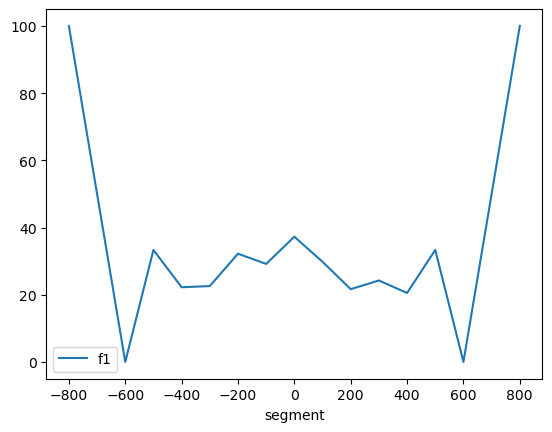

In [154]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'match_stat_predict', stat_clf, X_train.columns, predict_parameters)

In [155]:
venue

,size,accuracy,f1,roi,segment
1,333,37.837838,36.044631,-8.594595,Home
0,333,37.837838,34.478805,-11.711712,Away


In [156]:
fi

,feature,importance,position
0,rating_difference,0.213394,0
1,result_difference_personal_meet,0.187495,1
2,loses,0.122511,2
3,wins,0.122099,3
4,fouls_ma,0.116285,4
5,corners_ma,0.109102,5
6,shots_on_goal_ma,0.108523,6
7,is_Home,0.020591,7
8,is_high_league,0.000000,8


In [157]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo
4,666,42.492492,36.249211,-11.106607,real_random_forest_elo
5,666,41.741742,37.688590,-7.741742,best_params_elo
6,666,42.342342,33.324782,-7.584084,with_pers_meets
7,666,43.543544,33.240452,-2.636637,pers_meets_hyperparams
8,666,37.837838,35.721012,-10.153153,with_match_stat


## Модель №10 (модель ва-банк)

In [158]:
td = test_data[['rating', 'opponent_rating']]
test_data['no_elo_propability'] = td.apply(lambda x: np.round(pf.elo_prob(x[0], x[1]),2), axis=1)

In [159]:
y_direct_no_elo = test_data['no_elo_propability'].apply(lambda x: pf.no_elo_prob_predict(x, 0.1))
work_data['direct_no_elo_predict'] = y_direct_no_elo.values

,size,accuracy,f1,roi,segment,model
0,666,26.126126,26.237624,-4.996997,1,direct_no_elo


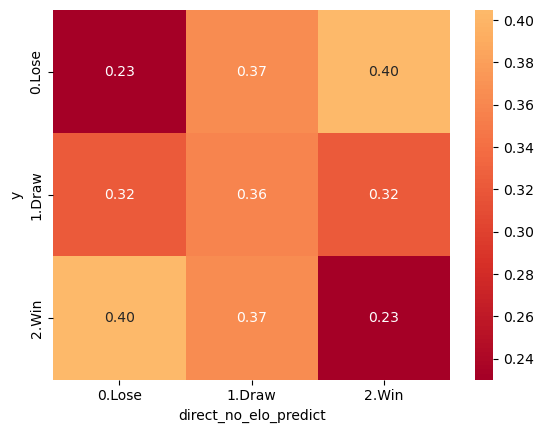

In [160]:
pf.model_results(work_data, 'direct_no_elo', 'direct_no_elo_predict', predict_parameters)

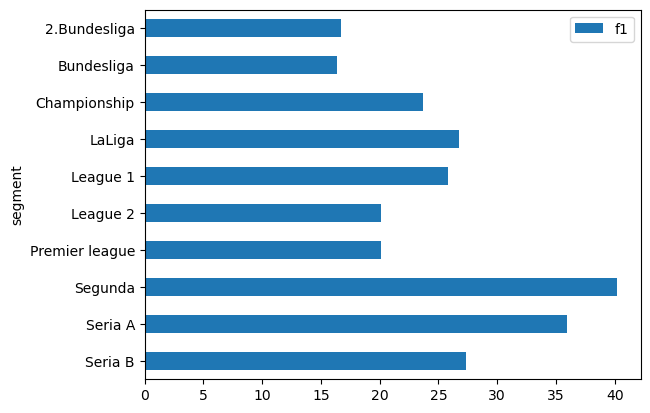

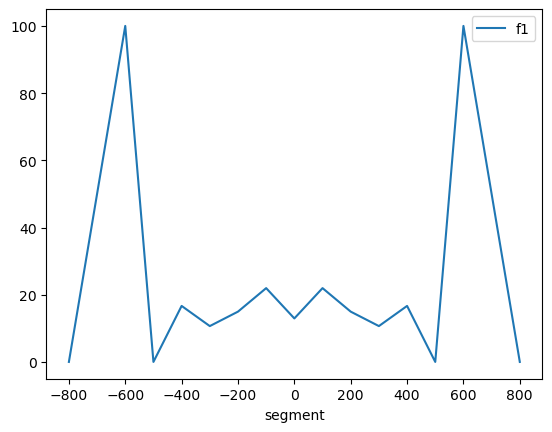

In [161]:
leagues, venue, fi, comparison_data = pf.watching(work_data, 'direct_no_elo_predict', '', [], predict_parameters)

## Итоговый результат рассмотренных моделей

In [162]:
comparison_data

,games,accuracy,f1,roi,model_name
0,666,34.234234,33.936446,-3.771772,random
1,666,37.837838,18.300654,-0.121622,simple_predict
2,666,39.339339,38.881302,-12.246246,direct_elo
3,666,41.891892,36.851324,-9.575075,random_forest_elo
4,666,42.492492,36.249211,-11.106607,real_random_forest_elo
5,666,41.741742,37.688590,-7.741742,best_params_elo
6,666,42.342342,33.324782,-7.584084,with_pers_meets
7,666,43.543544,33.240452,-2.636637,pers_meets_hyperparams
8,666,37.837838,35.721012,-10.153153,with_match_stat
9,666,26.126126,26.237624,-4.996997,direct_no_elo
